<a href="https://colab.research.google.com/github/juzology/python-for-data-analysis/blob/main/data-analysis-with-python-zero-to-pandas/course-project/zerotopandas-course-project-starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

FIFA World Cup Analysis

A data analysis project on the FIFA world cup trends since its inception to 2022 covering nine decades of the world cup history and the national team rankings as at June 2026: the dataset was gotten from kaggle, and we are analysing using python programming language; methods and techniques we've learned from the course  [Data Analysis with Python: Zero to Pandas](zerotopandas.com)

In [13]:
!pip install opendatasets --upgrade --quiet

Let's begin by downloading the data, and listing the files within the dataset.

In [14]:
dataset_url = 'https://www.kaggle.com/datasets/piterfm/fifa-football-world-cup'

In [15]:
import opendatasets as od
od.download(dataset_url)

Skipping, found downloaded files in "./fifa-football-world-cup" (use force=True to force download)


The dataset has been downloaded and extracted.

In [16]:
data_dir = './fifa-football-world-cup'

In [17]:
import os
os.listdir(data_dir)

['fifa_ranking_2022-10-06.csv',
 'fifa_ranking_2026-06-08.csv',
 'world_cup.csv',
 'schedule_2026.csv',
 'matches_1930_2022.csv']

## Data Preparation and Cleaning

We have now loaded our datasets into their respective data frames, displaying each data frame to give us a good overview of the of nature and contents of our dataset which will shall be referencing throughout the course of this project. We also included a goals columns by spliting the topScorer column which could be used for some analysis


In [18]:
import pandas as pd

In [119]:
world_cup_df = pd.read_csv('./fifa-football-world-cup/world_cup.csv')
world_cup_df

,Year,Host,Teams,Champion,Runner-Up,TopScorrer,Attendance,AttendanceAvg,Matches
0,2022,Qatar,32,Argentina,France,Kylian Mbappé - 8,3404252,53191,64
1,2018,Russia,32,France,Croatia,Harry Kane - 6,3031768,47371,64
2,2014,Brazil,32,Germany,Argentina,James Rodríguez - 6,3429873,53592,64
3,2010,South Africa,32,Spain,Netherlands,"Wesley Sneijder, Thomas Müller... - 5",3178856,49670,64
4,2006,Germany,32,Italy,France,Miroslav Klose - 5,3352605,52384,64
5,2002,"Korea Republic, Japan",32,Brazil,Germany,Ronaldo - 8,2705337,42271,64
6,1998,France,32,France,Brazil,Davor Šuker - 6,2903477,45367,64
7,1994,United States,24,Brazil,Italy,"Hristo Stoichkov, Oleg Salenko - 6",3587538,68991,52
8,1990,Italy,24,West Germany,Argentina,Salvatore Schillaci - 6,2516215,48389,52
9,1986,Mexico,24,Argentina,West Germany,Gary Lineker - 6,2394031,46039,52


In [121]:
world_cup_df[['Topscorer','Goals']] = world_cup_df['TopScorrer'].str.rsplit('-', n=1, expand=True)
world_cup_df['Goals'] = world_cup_df['Goals'].astype(int)
world_cup_df.drop(columns=['TopScorrer'], inplace=True)
world_cup_df

,Year,Host,Teams,Champion,Runner-Up,Attendance,AttendanceAvg,Matches,Topscorer,Goals
0,2022,Qatar,32,Argentina,France,3404252,53191,64,Kylian Mbappé,8
1,2018,Russia,32,France,Croatia,3031768,47371,64,Harry Kane,6
2,2014,Brazil,32,Germany,Argentina,3429873,53592,64,James Rodríguez,6
3,2010,South Africa,32,Spain,Netherlands,3178856,49670,64,"Wesley Sneijder, Thomas Müller...",5
4,2006,Germany,32,Italy,France,3352605,52384,64,Miroslav Klose,5
5,2002,"Korea Republic, Japan",32,Brazil,Germany,2705337,42271,64,Ronaldo,8
6,1998,France,32,France,Brazil,2903477,45367,64,Davor Šuker,6
7,1994,United States,24,Brazil,Italy,3587538,68991,52,"Hristo Stoichkov, Oleg Salenko",6
8,1990,Italy,24,West Germany,Argentina,2516215,48389,52,Salvatore Schillaci,6
9,1986,Mexico,24,Argentina,West Germany,2394031,46039,52,Gary Lineker,6


In [20]:
fifa_ranking_df = pd.read_csv('./fifa-football-world-cup/fifa_ranking_2026-06-08.csv')
fifa_ranking_df

,team,team_code,association,rank,previous_rank,points,previous_points,rated_matches
0,Argentina,ARG,CONMEBOL,1,3,1876.118331,1874.814835,59
1,Spain,ESP,UEFA,2,2,1873.013187,1876.395199,56
2,France,FRA,UEFA,3,1,1869.428449,1877.322731,57
3,England,ENG,UEFA,4,4,1827.048678,1825.965482,57
4,Portugal,POR,UEFA,5,5,1766.177547,1763.834406,56
...,...,...,...,...,...,...,...,...
206,Bahamas,BAH,CONCACAF,207,207,786.816217,786.816217,23
207,US Virgin Islands,VIR,CONCACAF,208,209,779.764266,779.764266,15
208,British Virgin Islands,VGB,CONCACAF,209,208,777.405734,782.137325,24
209,Anguilla,AIA,CONCACAF,210,210,760.251852,760.251852,18


In [63]:
world_cup_df.describe()

,Year,Teams,Attendance,AttendanceAvg,Matches
count,22.000000,22.000000,2.200000e+01,22.000000,22.000000
mean,1978.909091,22.363636,2.002201e+06,42728.545455,43.818182
std,27.738419,7.454915,1.101740e+06,12136.930791,17.632860
min,1930.000000,13.000000,3.630000e+05,20872.000000,17.000000
25%,1959.000000,16.000000,9.311905e+05,34749.000000,32.000000
50%,1980.000000,20.000000,1.987738e+06,46705.000000,45.000000
75%,2001.000000,32.000000,2.999695e+06,49527.250000,64.000000
max,2022.000000,32.000000,3.587538e+06,68991.000000,64.000000


In [98]:
world_cup_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Year                22 non-null     int64 
 1   Host                22 non-null     object
 2   Teams               22 non-null     int64 
 3   Champion            22 non-null     object
 4   Runner-Up           22 non-null     object
 5   TopScorrer          22 non-null     object
 6   Attendance          22 non-null     int64 
 7   AttendanceAvg       22 non-null     int64 
 8   Matches             22 non-null     int64 
 9   (Topscorer, Goals)  22 non-null     object
 10  Topscorer           22 non-null     object
 11  Goals               22 non-null     int64 
dtypes: int64(6), object(6)
memory usage: 2.2+ KB


In [25]:
fifa_ranking_df.describe()

,rank,previous_rank,points,previous_points,rated_matches
count,211.00000,211.00000,211.000000,211.000000,211.000000
mean,106.00000,106.00000,1229.980217,1229.968368,45.900474
std,61.05462,61.05462,278.045705,277.802985,16.301754
min,1.00000,1.00000,722.933728,726.330601,7.000000
25%,53.50000,53.50000,1010.838116,1008.017114,35.000000
50%,106.00000,106.00000,1191.655395,1191.416122,48.000000
75%,158.50000,158.50000,1455.740658,1455.577884,56.000000
max,211.00000,211.00000,1876.118331,1877.322731,87.000000


In [65]:
fifa_ranking_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211 entries, 0 to 210
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   team             211 non-null    object 
 1   team_code        211 non-null    object 
 2   association      211 non-null    object 
 3   rank             211 non-null    int64  
 4   previous_rank    211 non-null    int64  
 5   points           211 non-null    float64
 6   previous_points  211 non-null    float64
 7   rated_matches    211 non-null    int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 13.3+ KB


## Exploratory Analysis and Visualization

In this session we will drawing be several chart types to display relationships across both datasets we explored in this project



Let's begin by importing`matplotlib.pyplot` and `seaborn`.

In [ ]:
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

sns.set_style('darkgrid')
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.figsize'] = (9, 5)
matplotlib.rcParams['figure.facecolor'] = '#00000000'

The below chart shows the points distribution across FIFA ranking. We imported the numpy library and used the arange function to delineate the points distribution

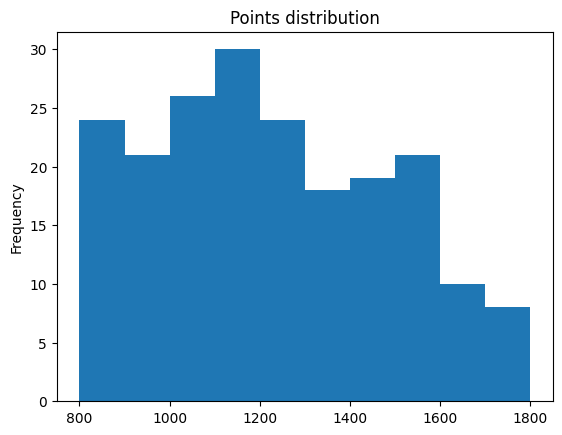

In [51]:
import numpy as np

fifa_ranking_df.points.plot(kind='hist',
                            title='Points distribution',
                            bins=np.arange(800,1900,100));

The below chart shows the number of matches played across the world cup

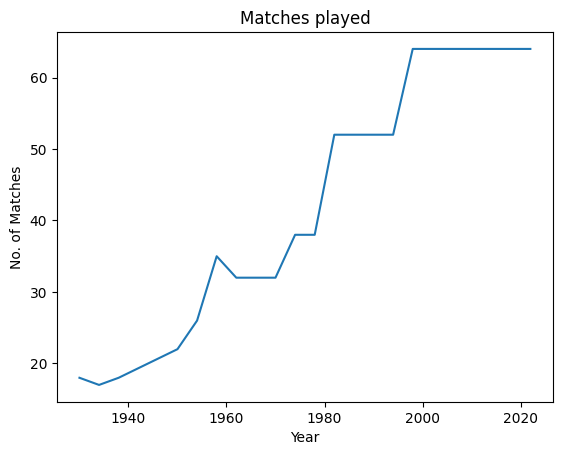

In [99]:
world_cup_df.set_index('Year')['Matches'].plot(kind='line',
                                             title='Matches played',
                                             xlabel='Year',
                                             ylabel='No. of Matches');

The below chart shows the rated matches across FIFA ranking

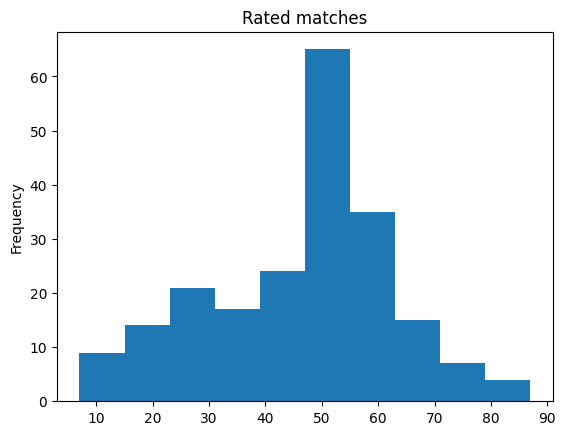

In [55]:
fifa_ranking_df.rated_matches.plot(kind='hist',
                            title='Rated matches');

The below chart shows the distribution of teams across thier respective associations under the FIFA governing body

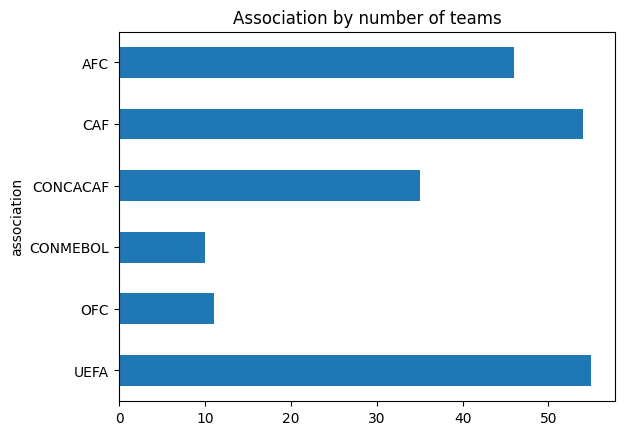

In [132]:
fifa_ranking_df['association'].value_counts().sort_index(ascending=False).plot(kind='barh',title='Association by number of teams');

The below chart shows the distribution of the highest number of goals scored by a single player in the world cup, we have also used the arange function to delineate the goals distribution

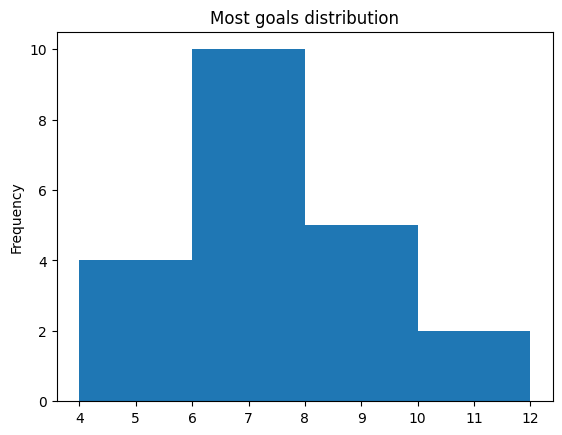

In [125]:
world_cup_df.Goals.plot(kind='hist',
                        title='Most goals distribution',
                        bins=np.arange(4, 14, 2));

## Asking and Answering Questions

In this session we will be using several chart types to answer some of the most interesting questions in the world of football analysis



What does the attendance trend look like in the world cup since its introduction to more recent years ?

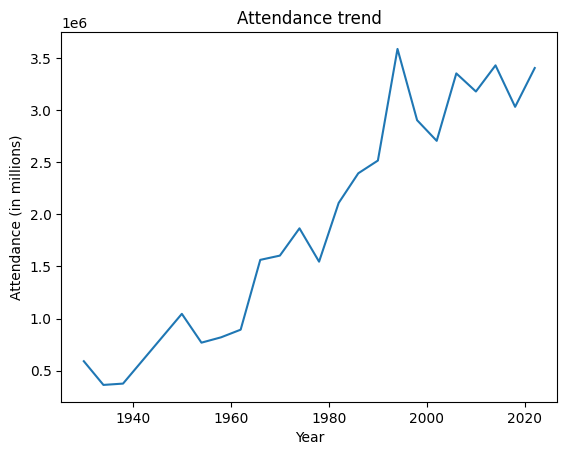

In [29]:
world_cup_df.set_index('Year')['Attendance'].plot(kind='line',
                             title='Attendance trend',
                             xlabel='Year',
                             ylabel='Attendance (in millions)');

The above is a line chart which show the world cup attendance trend. We used the set_index method to make the year column our index rather than the default index which is found in the dataset

Which countries have won the most trophies in the world cup ?

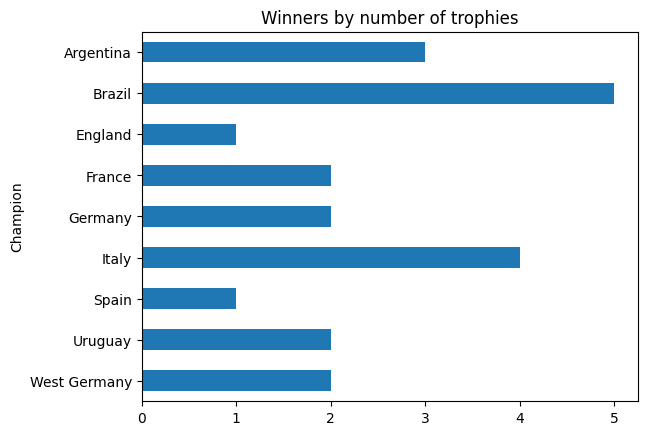

In [30]:
world_cup_df['Champion'].value_counts().sort_index(ascending=False).plot(kind='barh',title='Winners by number of trophies');

The above is a horizontal bar chart which shows the world cup winners by their number of trophies held. We used the value_counts method to show the number of times countries were repeated in the champion column and then we used the sort_index method to arrange the list in an alphabetical order.

What is the trend in the number of team participation in the world cup ?

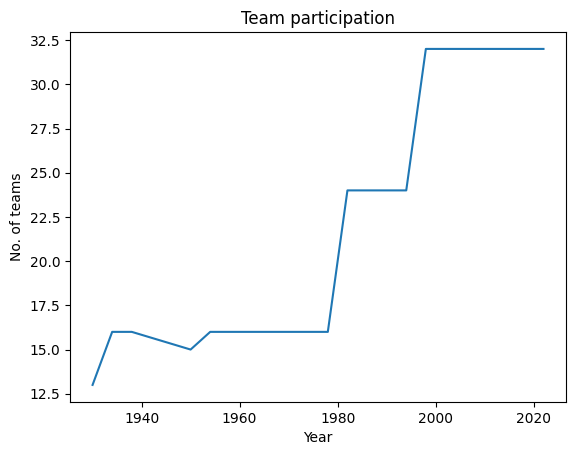

In [59]:
world_cup_df.set_index('Year')['Teams'].plot(kind='line',
                                             title='Team participation',
                                             xlabel='Year',
                                             ylabel='No. of teams');

The above is a line chart which shows the trend in the number of teams that have participated in the world cup over the years

What is the goal trend in terms of the highest number of goals scored by a single player ?

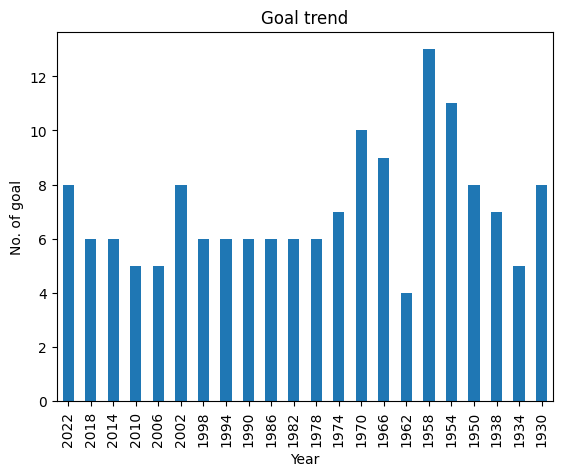

In [104]:
world_cup_df.set_index('Year')['Goals'].plot(kind='bar',
                                             title='Goal trend',
                                             xlabel='Year',
                                             ylabel='No. of goal');

The above is bar chart which shows the goal trend in terms of the highest number of goals scored by a single player in a world cup

What is the distribution of team across their respective association/regions of the world within the FIFA governing body ?

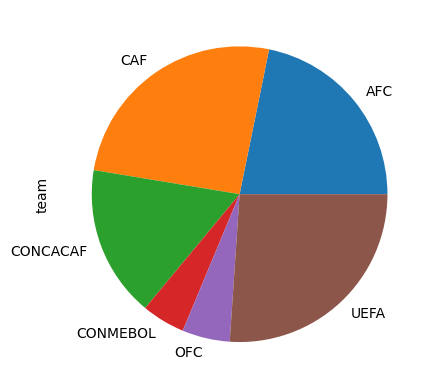

In [131]:
fifa_ranking_df.groupby('association')['team'].count().plot(kind='pie');

The above is a pie chart which shows the team distribution across thier respective associations governed by FIFA

## Inferences and Conclusion

One important point to note that that this analysis does not include the just concluded 2026 FIFA world cup data and as such some of the conclusion drawn is likely to have changed in comparison with the most recent dataset. Albeit, we can see an upward trend both in the number of teams that have participated over the years and the number of matches played. There is also an upward trend in the number of attendance recorded over the years and this seems to suggest an increased popularity in the competition

## References and Future Work

https://www.kaggle.com/ is not only useful for finding datasets, but also features some of the most recent trends in analytics, AI, machine learning, data science and other related topics; highly recommended for all data enthusiast.